# Mach-Zehnder Interferometer on a Chip

A **directional coupler** is the beam splitter of integrated photonics: two waveguides run close together, and light leaks from one into the other. A coupler that sends half of the power into each output is the on-chip version of a 50:50 beam splitter. Two such couplers joined by two waveguide arms form a **Mach-Zehnder interferometer (MZI)**. MZIs with tunable arms are the unit cell of programmable photonic circuits, including photonic quantum processors [3].

In this challenge you first optimize a directional coupler towards a 50:50 split at 1550 nm. Then you use two copies of it to build an MZI, and choose the arm length difference so that all light leaves through one output port. The quality of the MZI is measured by its **extinction ratio**, and the extinction ratio is limited by how close the coupler is to 50:50.

This notebook gives you a working design. It shows how to:

- compute the guided mode of a silicon waveguide,
- estimate the coupling length of a directional coupler from the modes of the coupled waveguides,
- simulate the coupler with the finite-difference time-domain (FDTD) method,
- assemble and simulate the MZI as a circuit,
- score the design against the challenge constraints.

You change four parameters: the waveguide width, the coupler gap, the coupling length and the arm length difference $\Delta L$.

**References**

1. Chrostowski, L., and Hochberg, M. *Silicon Photonics Design: From Devices to Systems*. Cambridge University Press, 2015, doi: [10.1017/CBO9781316084168](https://doi.org/10.1017/CBO9781316084168).
2. Yariv, A. "Coupled-mode theory for guided-wave optics." *IEEE Journal of Quantum Electronics* 1973 9 (9), 919-933, doi: [10.1109/JQE.1973.1077767](https://doi.org/10.1109/JQE.1973.1077767).
3. Carolan, J., *et al*. "Universal linear optics." *Science* 2015 349 (6249), 711-716, doi: [10.1126/science.aab3642](https://doi.org/10.1126/science.aab3642).

## Physics primer

**Waveguide modes.** A silicon strip waveguide (refractive index about 3.48) surrounded by silica (about 1.44) guides light by total internal reflection. Each guided mode travels with an **effective index** $n_{eff}$: its phase advances by $2\pi n_{eff} L / \lambda$ over a length $L$ at the vacuum wavelength $\lambda$.

**Directional coupler.** When two identical waveguides are placed a small gap apart, their modes overlap and combine into two **supermodes** of the pair: an even one, with the field in phase in both guides, and an odd one, with opposite signs [2]. The two supermodes travel with slightly different effective indices, $n_{even}$ and $n_{odd}$. Light launched into one waveguide excites both supermodes equally, and as they drift out of phase the power moves into the other waveguide. After a length $L$ the fraction of power in the other waveguide (the **cross port**) is

$$P_{cross} = \sin^2\left(\frac{\pi\,\Delta n\,L}{\lambda}\right), \qquad \Delta n = n_{even} - n_{odd}.$$

A 50:50 split needs $\pi \Delta n L / \lambda = \pi/4$, so the required straight coupling length is

$$L_{50} = \frac{\lambda}{4\,\Delta n}.$$

The S-bends that bring the waveguides together and apart also couple some light, because the gap there is still small. The real straight section is therefore shorter than $L_{50}$.

**Design levers.** The evanescent field decays exponentially outside the core, so $\Delta n$ falls roughly exponentially as the gap grows. A narrower waveguide confines the mode less, which spreads the field further into the gap and increases $\Delta n$. Because $\Delta n$ and $\lambda$ both change with wavelength, the split also drifts across the band, which is what the stretch goal measures.

**Mach-Zehnder interferometer.** The first coupler splits the input between two arms. The arms differ in length by $\Delta L$, which adds a phase difference

$$\Delta\varphi = \frac{2\pi\,n_{eff}\,\Delta L}{\lambda}.$$

The second coupler recombines the two beams. With ideal 50:50 couplers the power in the bright output is

$$P_{out} = \cos^2\left(\frac{\Delta\varphi}{2}\right),$$

so all light exits one port when $\Delta\varphi$ is a whole multiple of $2\pi$. With $\Delta L = 0$ that port is the cross port of the MZI.

**Extinction ratio.** If the couplers send a fraction $k$ to the cross port instead of exactly one half, the two paths no longer cancel perfectly in the dark port. For $\Delta\varphi = 2\pi m$ the dark port receives $(1 - 2k)^2$ of the power, and the **extinction ratio**, the ratio of bright to dark output power, is

$$ER = 10 \log_{10}\frac{4k(1-k)}{(1 - 2k)^2}\ \text{dB}.$$

For example, $k = 0.49$ gives 34 dB, and $k = 0.495$ gives 40 dB, the cap of the score.

## Imports

In [ ]:
%pip install pennylane # Pennylane needs to be installed for our application section

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import photonforge as pf
import tidy3d as td
from photonforge.live_viewer import LiveViewer

# Start the interactive layout viewer
viewer = LiveViewer()

# We raise the Tidy3D logging level to reduce output noise from the
# simulations below. Warnings can flag real problems, so only suppress them
# once you have confirmed they are not relevant to your case.
td.config.logging.level = "ERROR"

LiveViewer started at http://127.0.0.1:35355. Call its 'stop()' method to free the port.


## Design parameters

These four values are the design. Keep each one inside its range. The starting values give a working coupler and MZI, but the coupler is far from 50:50, so the starting score is zero.

In [2]:
# Width of the silicon waveguides, allowed range 0.40 to 0.55 (μm)
width = 0.5

# Gap between the two waveguides in the coupler, allowed range 0.10 to 0.40 (μm)
gap = 0.2

# Length of the straight coupling section, allowed range 0 to 30 (μm)
coupling_length = 0.0

# Arm length difference of the MZI, allowed range 0 to 100 (μm)
delta_length = 0.515

# Internal parameters for the double coupler design, used with the original parameters
# These variables only record the final values; they are not used in the code
L1 = 9.8
L2 = 5.45
gap_phase = 0.3
width_narrow = 0.4
width_wide = 0.55
taper = 1.0

The rest of the layout is fixed. The S-bends of the coupler are 10 µm long and move each waveguide 2 µm sideways. The two couplers of the MZI sit 150 µm apart, and the MZI arms use a 10 µm bend radius. The simulations cover the telecom C band, 1530 to 1565 nm, in 1 nm steps.

In [3]:
s_bend_length = 10.0  # Length of each coupler S-bend (μm)
s_bend_offset = 2.0  # Lateral offset of each coupler S-bend (μm)
arm_length = 150.0  # Distance between the two couplers of the MZI (μm)
arm_radius = 10.0  # Bend radius of the MZI arms (μm)

# Wavelengths of the simulations (μm) and the corresponding frequencies (Hz)
wavelengths = np.linspace(1.530, 1.565, 36)
frequencies = pf.C_0 / wavelengths

# Index of the 1550 nm design wavelength
i_1550 = np.argmin(np.abs(wavelengths - 1.550))

## Technology and waveguide mode

PhotonForge's built-in [basic technology](https://docs.flexcompute.com/projects/photonforge/en/latest/_autosummary/photonforge.basic_technology.html) is a silicon-on-insulator platform: a 220 nm silicon layer on a 2 µm buried oxide, covered by silica. Its `"Strip"` port specification describes a strip waveguide, and the `strip_width` argument sets the waveguide width used everywhere below.

In [4]:
# Silicon-on-insulator technology with the chosen waveguide width
technology = pf.basic_technology(strip_width=width)
pf.config.default_technology = technology

# Port specification of the strip waveguide
strip = technology.ports["Strip"]
strip

PortSpec(description="Strip waveguide", width=2.25, limits=(-1, 1.22), num_modes=1, added_solver_modes=0, polarization="", target_neff=0, default_radius=0, path_profiles=[(0.5, 0, (2, 0)), (2.5, 0, (1, 0))])

The next cell solves for the fundamental transverse-electric (TE) mode of the strip waveguide across the band. The effective index sets the phase of the MZI arms. The group index $n_g$ sets the free spectral range of the MZI, the wavelength spacing between its transmission peaks, $\lambda^2 / (n_g \Delta L)$.

Uploading task 'Mode-ModeSolver…'
Starting task 'Mode-ModeSolver': https://tidy3d.simulation.cloud/workbench?taskId=mo-94d33213-7ffe-40fc-ac78-a866ba921a45
Progress: 100% 
Effective index at 1550 nm: 2.4401
Group index at 1550 nm: 4.1811


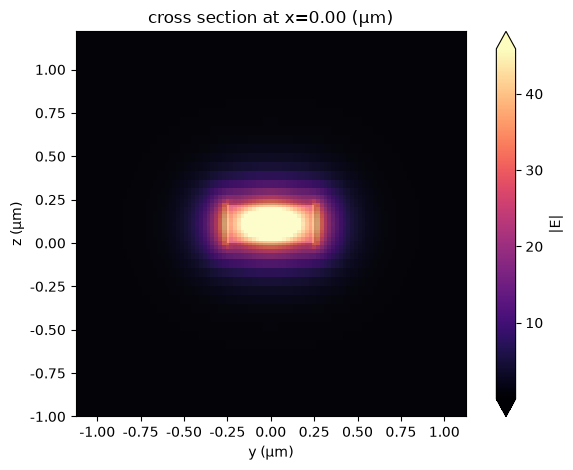

In [5]:
# Solve for the strip waveguide mode across the band
strip_modes = pf.port_modes("Strip", frequencies, group_index=True)

# Effective and group indices at 1550 nm
n_eff = strip_modes.data.n_eff.isel(mode_index=0).values[i_1550]
n_group = strip_modes.data.n_group.isel(mode_index=0).values[i_1550]
print(f"Effective index at 1550 nm: {n_eff:.4f}")
print(f"Group index at 1550 nm: {n_group:.4f}")

# Field magnitude of the mode at 1550 nm
_ = strip_modes.plot_field("E", "abs", mode_index=0, f=frequencies[i_1550])

## Coupling length estimate

The supermodes of the coupler come from a mode solve of a cross-section with both waveguides, a distance `width + gap` apart. This port specification is built only for the estimate, with two modes and the starting guess of the solver set to the silicon index. The estimate costs one mode solve, so it is a cheap way to explore the gap and width before you spend an FDTD run.

In [6]:
# Distance between the two waveguide centres in the coupler (μm)
coupling_distance = width + gap

# Cross-section with both waveguides and the silica cladding around them
coupled_strips = pf.PortSpec(
    description="Coupled strips",
    width=strip.width + coupling_distance,
    limits=strip.limits,
    num_modes=2,
    target_neff=3.5,
    path_profiles=[
        (width, coupling_distance / 2, "WG_CORE"),
        (width, -coupling_distance / 2, "WG_CORE"),
        (strip.path_profiles[1][0] + coupling_distance, 0, "WG_CLAD"),
    ],
)

# Solve for the even and odd supermodes at 1550 nm
supermodes = pf.port_modes(coupled_strips, [frequencies[i_1550]])
n_even, n_odd = supermodes.data.n_eff.values.ravel()

# Straight coupling length for a 50:50 split, without the S-bends (μm)
l_50 = 1.550 / (4 * (n_even - n_odd))
print(f"Supermode indices: {n_even:.4f} (even), {n_odd:.4f} (odd)")
print(f"Estimated 50:50 coupling length without the S-bends: {l_50:.1f} μm")

Uploading task 'Mode-ModeSolver…'
Starting task 'Mode-ModeSolver': https://tidy3d.simulation.cloud/workbench?taskId=mo-7506552f-c19a-47a5-8e87-6b17254f3dce
Progress: 100% 
Supermode indices: 2.4507 (even), 2.4296 (odd)
Estimated 50:50 coupling length without the S-bends: 18.3 μm


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3), tight_layout=True)

# Lateral field component of the even and odd supermodes
for m, name in enumerate(("Even", "Odd")):
    supermodes.plot_field("Ey", "real", mode_index=m, f=frequencies[i_1550], ax=ax[m])
    ax[m].set_title(f"{name} supermode")
plt.show()

## Directional coupler

The coupler is PhotonForge's [s_bend_coupler](https://docs.flexcompute.com/projects/photonforge/en/latest/_autosummary/photonforge.parametric.s_bend_coupler.html): two S-bends bring the waveguides to the gap, a straight section couples them, and two more S-bends separate them again. Its ports are:

- `P0`, bottom left, the input,
- `P1`, top left,
- `P2`, bottom right, the **through** port,
- `P3`, top right, the **cross** port.

The coupler is simulated with a [Tidy3DModel](https://docs.flexcompute.com/projects/photonforge/en/latest/_autosummary/photonforge.Tidy3DModel.html), which runs 3D FDTD. The coupler is mirror symmetric left to right and top to bottom, so every column of its scattering matrix follows from the single run with light entering `P0`. The `port_symmetries` argument lists these port swaps. The mesh uses 12 cells per wavelength (`grid_spec=12`), which keeps one run to about a minute.

Each S-bend is made of two circular arcs. For an S-bend of length $L_s$ and offset $H$, their radius is

$$R = \frac{L_s^2 + H^2}{4H}.$$



**NOTE**: This section is not our final design. We used this section during our design process, but decided to design a different coupler in the next section.

In [23]:
@pf.parametric_component
def directional_coupler(
    *,
    gap: float = 0.2,
    coupling_length: float = 5.0,
    s_bend_length: float = 10.0,
    s_bend_offset: float = 2.0,
):
    # Waveguide width taken from the strip port specification (μm)
    core_width = pf.config.default_technology.ports["Strip"].path_profiles[0][0]

    # Port swaps under the left-right, top-bottom and combined mirror symmetries
    port_symmetries = [
        ("P1", "P0", "P3", "P2"),
        ("P2", "P3", "P0", "P1"),
        ("P3", "P2", "P1", "P0"),
    ]

    # S-bend coupler simulated with FDTD
    return pf.parametric.s_bend_coupler(
        port_spec="Strip",
        coupling_distance=core_width + gap,
        s_bend_length=s_bend_length,
        s_bend_offset=s_bend_offset,
        coupling_length=coupling_length,
        model=pf.Tidy3DModel(port_symmetries=port_symmetries, grid_spec=12),
    )


# Build the coupler for the current design parameters
# coupling_length = 0.0
coupler = directional_coupler(
    gap=gap,
    coupling_length=0.0,
    s_bend_length=s_bend_length,
    s_bend_offset=s_bend_offset,
)
viewer(coupler)

In [24]:
# Radius of the circular arcs in the coupler S-bends (μm)
s_bend_radius = (s_bend_length**2 + s_bend_offset**2) / (4 * s_bend_offset)
print(f"S-bend radius: {s_bend_radius:.1f} μm")

S-bend radius: 13.0 μm


The next cell builds the FDTD simulation without running it, plots it from the top and from the side, and asks the server for the cost of the run. Check the cost against your team's budget before you run.

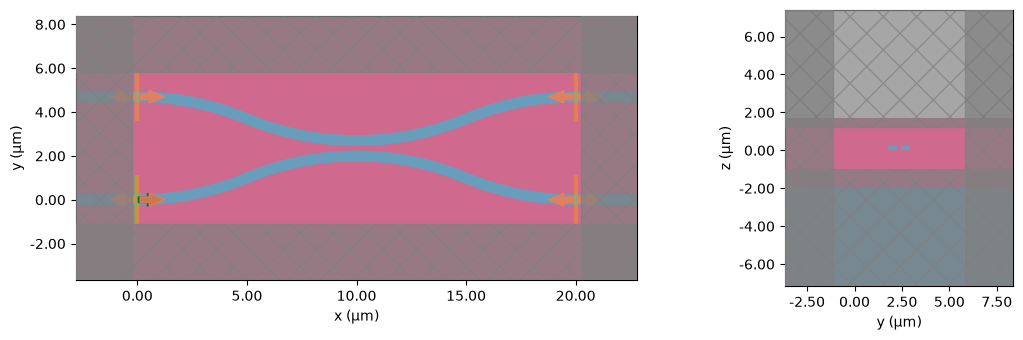

Uploading task 'P0@0…'
Estimated cost for task 'P0@0: 1.352339836654834'


In [25]:
# FDTD simulation with light entering P0
simulation = coupler.active_model.get_simulations(coupler, frequencies)["P0@0"]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), tight_layout=True)

# Top view through the middle of the silicon layer
simulation.plot(z=0.11, ax=ax[0])

# Side view through the middle of the coupling section
simulation.plot(x=simulation.center[0], ax=ax[1])
for a in ax:
    a.set_title("")
plt.show()

# Maximum cost of the run in FlexCredits
cost = coupler.active_model.estimate_cost(coupler, frequencies)

The next cell submits the FDTD run and waits for it. PhotonForge caches the result, so running the cell again with the same design costs nothing.

In [26]:
# Scattering matrix of the coupler from one FDTD run
s_coupler = coupler.s_matrix(frequencies)

Uploading task 'P0@0…'
Starting task 'P0@0': https://tidy3d.simulation.cloud/workbench?taskId=fdve-120b6d2d-063d-474d-ac18-58efef160bab
Progress: 100% 


In [27]:
# Power in the through and cross ports for light entering P0
through = np.abs(s_coupler["P0@0", "P2@0"]) ** 2
cross = np.abs(s_coupler["P0@0", "P3@0"]) ** 2

# Split ratio: share of the output power in the cross port (in decimal, not %)
split = cross[i_1550] / (through[i_1550] + cross[i_1550])

#
phi = np.arcsin(np.sqrt(split)) #I'm isolating phi from the p_cross formula
kappa = np.pi * (n_even - n_odd) / 1.550 #This is kappa value from the kappa = (delta_n*pi)/lambda using the n_even and n_odd thing to convert the S-bend effect into a length of φ/κ, it's gonna predict the the 50:50 length
L_50 = (np.pi / 4 - phi) / kappa #this is the kappa and phi relation to be able to predict the length

# Display the results
print(f"S-bends P_cross {100*split:.2f} % of the light")
print(f"phi = {phi:.3f} rad, kappa = {kappa:.4f} /µm")
print(f"S-bends act like {phi/kappa:.2f} µm of extra coupler")
print(f"→ predicted 50:50 coupling length: {L_50:.2f} µm")

S-bends P_cross 1.25 % of the light
phi = 0.112 rad, kappa = 0.0429 /µm
S-bends act like 2.61 µm of extra coupler
→ predicted 50:50 coupling length: 15.68 µm


## Double Coupler
The MZI uses a double coupler instead. The double coupler design has a section of asymmetric waveguides that have different widths. This design yields a better tolerance of the split ratio across different wavelengths. w_wide and w_narrow are the widths of the waveguides in the asymmetric section.

In [7]:
# New asymmetric coupler design
@pf.parametric_component
def double_coupler(*, gap=0.2, L1=12.4, L2=4.6, w_wide=0.55, w_narrow=0.4, gap_phase=0.3, taper=1.0, s_bend_length=10.0, s_bend_offset=2.0):
    tech = pf.config.default_technology
    spec = tech.ports["Strip"]
    w0 = spec.path_profiles[0][0] #w0 is whatever width we choose and it w0 is a variable inside double_coupler that holds the normal waveguide width and it updates any time we change it
    y_bot = s_bend_offset #y position bottom and top for the two symmetric couplers
    y_top = s_bend_offset + w0 + gap
    y_top_p = (y_top - w0/2 + w_narrow/2) - (gap - gap_phase)/2 #these are the centre lines in the phase section between the symmetric ones, this places the narrow top waveguide
    y_bot_p = y_top_p - w_narrow/2 - gap_phase - w_wide/2 #this places the wide bottom waveguide below wg1
    x = [0.0] #This adds up the section lengths to get where each one starts and ends along x axis the total is 51.4 um
    
    for length in (s_bend_length, L1, taper, L2, taper, L1, s_bend_length):
        x.append(x[-1] + length)
        x_end = x[-1] 
    
    c = pf.Component("Double_Coupler", technology=tech) #from photonforge, it creates an empty component to draw from

    def build(y_port, y_sym, y_phase, w_phase): #this is the function to build the double coupler
        for layer, path in spec.get_paths((0, y_port)): #get_paths gives us the waveguide’s drawing paths starting at the port one for the silicon core and one for the layer around it
            dw = w_phase - w0 #How much the waveguide gets wider or narrower in the phase section, 0.1 for the bottom guide, −0.1 for the top
            path.s_bend((x[1], y_sym)) #The s-bend in then the straight first symmetric section L1
            path.segment((x[2], y_sym))
            base = [p for p in spec.path_profiles if tuple(p[2]) == tuple(layer)][0][0] #this is from photonforge, this layer’s normal width 0.5 for the core, 2.5 for the layer. The segment goes from L1’s end to the phase section’s start, shifting its centre to y_phase and changing its width by dw
            path.segment((x[3], y_phase), width=base + dw) #Because segment changes width by default, this is the 1 um tapered waveguide connection from the research paper's design
            path.segment((x[4], y_phase)) #The straight phase section L2, the taper to symmetric width, the second symmetric section L1, and the S-bend back to the port’s y position. 
            path.segment((x[5], y_sym), width=base)
            path.segment((x[6], y_sym))
            path.s_bend((x[7], y_port))
            c.add(layer, path)#c.add puts the finished path into the component through photonforge.
    
    build(0.0, y_bot, y_bot_p, w_wide)#this is building bottom guide on the y-axis from 0 point, the symmetric coupler length and the phase wg length, and then the widht
    build(2*s_bend_offset + w0 + gap, y_top, y_top_p, w_narrow) #this is building the top. 
            
    y_out_top = 2 * s_bend_offset + w0 + gap 
    c.add_port(pf.Port((0, 0), 0, spec))#Port 0 bottom-left input from photonforge adds the four ports to the design
    c.add_port(pf.Port((0, y_out_top), 0, spec))#Port 1 top-left input
    c.add_port(pf.Port((x_end, 0), 180, spec, inverted=True))#P2 bottom-right output
    c.add_port(pf.Port((x_end, y_out_top), 180, spec, inverted=True)) #Port 3 top-right output
    
    #The starter’s coupler uses pf.Tidy3DModel(port_symmetries=..., grid_spec=12) with three symmetries. But we only need the vertical one P0 P2 and P1P3, because the top and bottom guides are diff, so the swap top and bottom symmetry is no longer true. 
    c.add_model(pf.Tidy3DModel(port_symmetries=[("P2", "P3", "P0", "P1")], grid_spec=12), "Tidy3D")#grid_spec=12 is the starter’s mesh setting
    return c

In [8]:
# Single-waveguide n_eff for the phase-section widths, mode solver from starter code
n_single = {}
for w in [0.40, 0.55, 0.60]:
    pf.config.default_technology = pf.basic_technology(strip_width=w)   # starter Technology cell
    m = pf.port_modes("Strip", [frequencies[i_1550]])                   # starter strip-mode cell
    n_single[w] = m.data.n_eff.values.ravel()[0]
    print(f"w = {w:.2f} µm → n_eff = {n_single[w]:.4f}")

pf.config.default_technology = technology   # restore your design (width 0.5)

dn_lu  = n_single[0.60] - n_single[0.40]   # Lu's widths
dn_new = n_single[0.55] - n_single[0.40]   # our in-range widths
L2_new = 4.6 * dn_lu / dn_new              # same phase as Lu's 4.6 µm section
print(f"Δn Lu = {dn_lu:.4f}, Δn ours = {dn_new:.4f} → L2_new = {L2_new:.2f} µm")

Uploading task 'Mode-ModeSolver…'
Starting task 'Mode-ModeSolver': https://tidy3d.simulation.cloud/workbench?taskId=mo-f84bd96c-e5bc-42a2-8a28-b5268a9f4384
Progress: 100% 
w = 0.40 µm → n_eff = 2.2224
Uploading task 'Mode-ModeSolver…'
Starting task 'Mode-ModeSolver': https://tidy3d.simulation.cloud/workbench?taskId=mo-8c4b3fd3-0806-45af-8d87-c9492160be56
Progress: 100% 
w = 0.55 µm → n_eff = 2.5075
Uploading task 'Mode-ModeSolver…'
Starting task 'Mode-ModeSolver': https://tidy3d.simulation.cloud/workbench?taskId=mo-140ce70d-6b9e-433c-804a-ac54f1f89145
Progress: 100% 
w = 0.60 µm → n_eff = 2.5599
Δn Lu = 0.3375, Δn ours = 0.2850 → L2_new = 5.45 µm


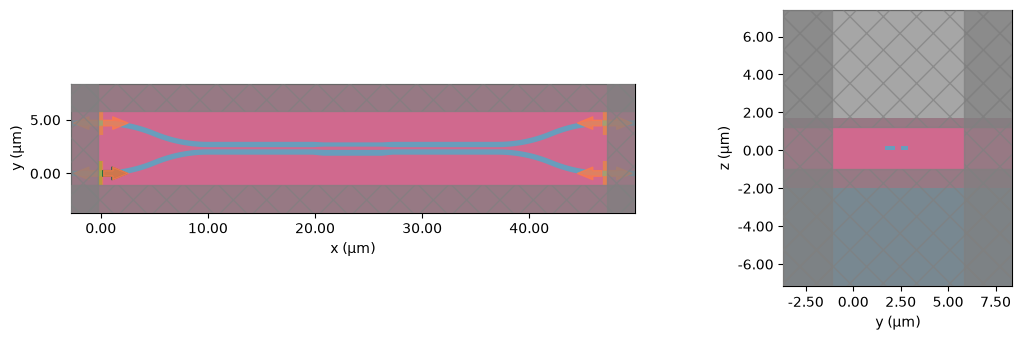

Uploading task 'P0@0…'
Uploading task 'P1@0…'
Estimated cost for task 'P0@0: 3.4198432305366544'
Estimated cost for task 'P1@0: 3.4198432305366544'


In [9]:
L1_test = 9.8 #we can change this and rerun to try another length
L2_test = L2_new #from the mode-solve

# Values used for final coupler components
L1_best = 9.8 #best L1 from testing
L2_best = L2_new #best L2

# Upload FDTD for the best double coupler design
double_coupler_component = double_coupler(gap=gap, L1=L1_best, L2=L2_best, w_wide=0.55, w_narrow=0.40)

simulation = double_coupler_component.active_model.get_simulations(double_coupler_component, frequencies)["P0@0"]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), tight_layout=True)

# Top view through the middle of the silicon layer
simulation.plot(z=0.11, ax=ax[0])

# Side view through the middle of the coupling section
simulation.plot(x=simulation.center[0], ax=ax[1])
for a in ax:
    a.set_title("")
plt.show()

# Maximum cost of the run in FlexCredits
cost = double_coupler_component.active_model.estimate_cost(double_coupler_component, frequencies)

In [20]:
viewer(double_coupler_component)

In [10]:
# Run the FDTD simulation
s_dc = double_coupler_component.s_matrix(frequencies)
through_dc = np.abs(s_dc["P0@0", "P2@0"]) ** 2 #through power 
cross_dc = np.abs(s_dc["P0@0", "P3@0"]) ** 2 #cross power 
split_dc = 100 * cross_dc / (through_dc + cross_dc) #split at every wavelength in %

print(f"L1 = {L1_best:.2f} µm, L2 = {L2_best:.2f} µm")
print(f"Split at 1550 nm: {split_dc[i_1550]:.2f} %")
print(f"Across band: {split_dc.min():.2f} % to {split_dc.max():.2f} %")

Uploading task 'P0@0…'
Uploading task 'P1@0…'
Starting task 'P0@0': https://tidy3d.simulation.cloud/workbench?taskId=fdve-f0967459-fd1c-422f-904d-842419f01b3b
Starting task 'P1@0': https://tidy3d.simulation.cloud/workbench?taskId=fdve-0d380976-58a8-4297-9501-5753fc0189de
L1 = 9.80 µm, L2 = 5.45 µmProgress: 100% 

Split at 1550 nm: 49.99 %
Across band: 47.48 % to 51.45 %


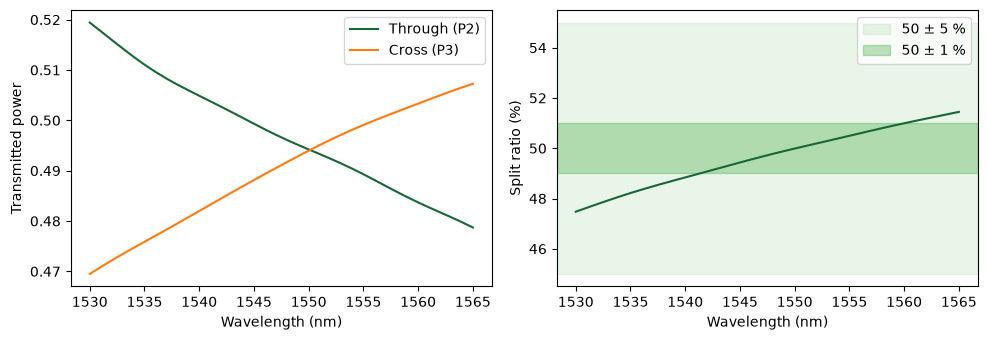

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), tight_layout=True)

# Through and cross power across the band
ax[0].plot(wavelengths * 1e3, through_dc, label="Through (P2)")
ax[0].plot(wavelengths * 1e3, cross_dc, label="Cross (P3)")
ax[0].set_xlabel("Wavelength (nm)")
ax[0].set_ylabel("Transmitted power")
ax[0].legend()

# Split ratio across the band with the 50 ± 1 % and 50 ± 5 % windows
ax[1].plot(wavelengths * 1e3, split_dc)
ax[1].axhspan(45, 55, color="tab:green", alpha=0.1, label="50 ± 5 %")
ax[1].axhspan(49, 51, color="tab:green", alpha=0.3, label="50 ± 1 %")
ax[1].set_xlabel("Wavelength (nm)")
ax[1].set_ylabel("Split ratio (%)")
ax[1].legend()
plt.show()

## Mach-Zehnder interferometer

The MZI places two copies of the coupler 150 µm apart and joins them with two arms. Both arms are drawn in a single call to [route_auto](https://docs.flexcompute.com/projects/photonforge/en/latest/_autosummary/photonforge.parametric.route_auto.html), PhotonForge's automatic router.

The arm length difference is stated as a target rather than drawn by hand. A [PathLengthMatching](https://docs.flexcompute.com/projects/photonforge/en/latest/_autosummary/photonforge.PathLengthMatching.html) group tells the router to equalize `offset + routed length` over the arms. Crediting the lower arm with an offset of $\Delta L$ therefore makes the router lengthen the upper arm by exactly $\Delta L$, which it does by inserting a meander of bends. The meander bends use the same 10 µm radius as the rest of the route.

The routed waveguides use waveguide models that take the effective index from a mode solve of the strip and the length from the layout. A [CircuitModel](https://docs.flexcompute.com/projects/photonforge/en/latest/_autosummary/photonforge.CircuitModel.html) then combines the scattering matrices of all parts, including the two copies of the FDTD coupler. The MZI therefore needs no new FDTD run.

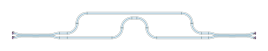

In [12]:
@pf.parametric_component
def mzi(
    *,
    gap: float = 0.2,
    L1: float,
    L2: float,
    delta_length: float = 10.0,
    s_bend_length: float = 10.0,
    s_bend_offset: float = 2.0,
    arm_length: float = 150.0,
    arm_radius: float = 10.0,
):
    # Create the MZI component
    interferometer = pf.Component("MZI")

    # Coupler used for both the splitter and the combiner
    coupler = double_coupler(
        gap=gap,
        L1=L1,
        L2=L2,
        w_wide=0.55,
        w_narrow=0.40
    )

    # Place the splitter at the origin and the combiner one arm length after it
    splitter = interferometer.add_reference(coupler)
    combiner = interferometer.add_reference(coupler)
    combiner.translate((splitter["P2"].center[0] + arm_length, 0))

    # Route both arms, making the upper arm longer than the lower one by delta_length
    arms = pf.parametric.route_auto(
        port1=[(splitter, "P2"), (splitter, "P3")],
        port2=[(combiner, "P0"), (combiner, "P1")],
        radius=arm_radius,
        matching=[pf.PathLengthMatching(offsets=[delta_length, 0.0])],
    )
    interferometer.add_reference(arms)

    # Expose the two inputs and two outputs and simulate the MZI as a circuit
    interferometer.add_port(
        [splitter["P0"], splitter["P1"], combiner["P2"], combiner["P3"]]
    )
    interferometer.add_model(pf.CircuitModel(), "Circuit")
    return interferometer


# Build the MZI for the current design parameters
device = mzi(
    gap=gap,
    L1=L1_best,
    L2=L2_best,
    delta_length=delta_length,
    s_bend_length=s_bend_length,
    s_bend_offset=s_bend_offset,
    arm_length=arm_length,
    arm_radius=arm_radius,
)
viewer(device)

The router reports nothing when it succeeds, so the next cell measures both arms with [route_length](https://docs.flexcompute.com/projects/photonforge/en/latest/_autosummary/photonforge.route_length.html) and prints the arm length difference it achieved. If a target cannot fit, the router leaves the arms unmatched, and this printout shows it.

In [13]:
# Routed arms inside the MZI, lower arm first
routes = next(
    ref.component for ref in device.references if ref.component.name != double_coupler_component.name
)

# Length of each routed arm (μm)
arm_lengths = [pf.route_length(ref.component) for ref in routes.references]

# Arm length difference achieved by the router (μm)
achieved_delta = arm_lengths[1] - arm_lengths[0]
print(f"Arm lengths: {arm_lengths[0]:.4f} μm (lower), {arm_lengths[1]:.4f} μm (upper)")
print(f"Arm length difference: {achieved_delta:.4f} μm (target {delta_length:.4f} μm)")

Arm lengths: 172.9132 μm (lower), 173.4292 μm (upper)
Arm length difference: 0.5160 μm (target 0.5150 μm)


The MZI ports follow the same convention as the coupler: `P0` and `P1` are the inputs on the left, and `P2` (bottom) and `P3` (top) are the outputs on the right. Light enters `P0`.

Uploading task 'Mode-Stripwaveguide…'
Uploading task 'Mode-Stripwaveguide…'
Uploading task 'Mode-Stripwaveguide…'
Uploading task 'Mode-Stripwaveguide…'
Uploading task 'Mode-Stripwaveguide…'
Uploading task 'Mode-Stripwaveguide…'
Starting task 'Mode-Stripwaveguide': https://tidy3d.simulation.cloud/workbench?taskId=mo-62e41c86-e9f1-4b93-81fa-03a9ed55e14f
Starting task 'Mode-Stripwaveguide': https://tidy3d.simulation.cloud/workbench?taskId=mo-5471a2ce-e3b5-42de-aae2-6da3cf310b89
Starting task 'Mode-Stripwaveguide': https://tidy3d.simulation.cloud/workbench?taskId=mo-79127dff-bd01-4f2a-b381-82987ad0ecaa
Starting task 'Mode-Stripwaveguide': https://tidy3d.simulation.cloud/workbench?taskId=mo-a7718b59-9b14-4443-903c-1a0f1e7bcbf6
Starting task 'Mode-Stripwaveguide': https://tidy3d.simulation.cloud/workbench?taskId=mo-44b42ff3-c464-4a6b-86ab-aa005f8255e7
Starting task 'Mode-Stripwaveguide': https://tidy3d.simulation.cloud/workbench?taskId=mo-0a5e8373-0afd-4e08-b0ce-d6abc6ff32e7
Arm phase differ

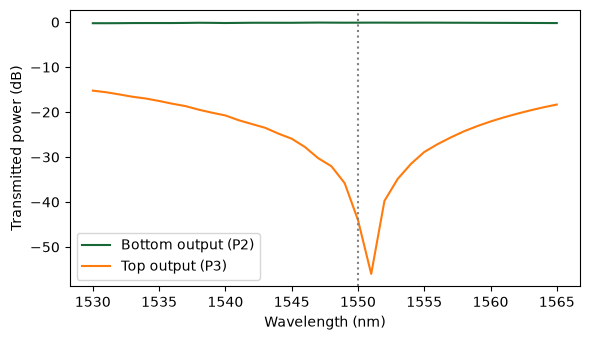

In [14]:
# Scattering matrix of the MZI from its parts
s_mzi = device.s_matrix(frequencies)

# Power in the two MZI outputs for light entering P0
p_bottom = np.abs(s_mzi["P0@0", "P2@0"]) ** 2
p_top = np.abs(s_mzi["P0@0", "P3@0"]) ** 2

# Extinction ratio at 1550 nm: bright output over dark output (dB)
bright = max(p_bottom[i_1550], p_top[i_1550])
dark = min(p_bottom[i_1550], p_top[i_1550])
extinction = 10 * np.log10(bright / dark)

# Phase difference between the arms at 1550 nm, in units of 2π
phase_cycles = n_eff * delta_length / 1.550
print(f"Arm phase difference at 1550 nm: {phase_cycles:.3f} × 2π")
print(f"Extinction ratio at 1550 nm: {extinction:.1f} dB")

fig, ax = plt.subplots(figsize=(6, 3.5), tight_layout=True)

# MZI outputs across the band in dB
ax.plot(wavelengths * 1e3, 10 * np.log10(p_bottom), label="Bottom output (P2)")
ax.plot(wavelengths * 1e3, 10 * np.log10(p_top), label="Top output (P3)")
ax.axvline(1550, color="gray", linestyle=":")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Transmitted power (dB)")
ax.legend()
plt.show()

## Score

The score function checks the coupler and fabrication constraints. If all of them pass, the score is the MZI extinction ratio at 1550 nm in dB, capped at 40. A coupler that also stays within 50 ± 5 % across 1530 to 1565 nm earns a bonus of 5 points.

In [17]:
def mzi_score(split, min_feature, min_radius, extinction):
    # Pass or fail for every constraint of the challenge
    checks = {
        "Coupler split ratio at 1550 nm within 50 ± 1 %": abs(split[i_1550] - 50) <= 1,
        "Minimum gap or feature at least 100 nm": min_feature >= 0.1,
        "Minimum bend radius at least 5 μm": min_radius >= 5,
    }

    # Stretch goal: split ratio within 50 ± 5 % across the whole band
    stretch = bool(np.all(np.abs(split - 50) <= 5))

    # Print the outcome of each check
    for name, passed in checks.items():
        print(f"{'PASS' if passed else 'FAIL'}  {name}")
    print(
        f"{'PASS' if stretch else 'FAIL'}  Stretch: split ratio within 50 ± 5 % from 1530 to 1565 nm"
    )

    # Capped extinction ratio plus the stretch bonus if every constraint passes
    if not all(checks.values()):
        return 0.0
    return min(extinction, 40.0) + (5.0 if stretch else 0.0)


# Smallest drawn feature or gap and the tightest bend of the layout (μm)
min_feature = min(width, gap, gap_phase, width_narrow) # Also consider the dimensions of the double coupler. However the min is still the original gap value; The double coupler does not impact the score here
min_radius = min(s_bend_radius, arm_radius)

# Score of the current design
score = mzi_score(split_dc, min_feature, min_radius, extinction)
print(f"\nScore: {score:.1f}")

PASS  Coupler split ratio at 1550 nm within 50 ± 1 %
PASS  Minimum gap or feature at least 100 nm
PASS  Minimum bend radius at least 5 μm
PASS  Stretch: split ratio within 50 ± 5 % from 1530 to 1565 nm

Score: 45.0


## Where to go from here

- **Coupler first.** The split ratio is the only constraint the starting design fails. Use the coupling length estimate to get close before you run FDTD: the S-bends add coupling, so the straight section you need is shorter than $L_{50}$. Two or three FDTD runs at different coupling lengths are enough to interpolate to 50:50, since $P_{cross}$ follows $\sin^2$ of the total coupling.
- **Then the arms.** Choose $\Delta L$ so that the phase difference at 1550 nm is a whole number of $2\pi$ cycles, using $\Delta\varphi = 2\pi n_{eff} \Delta L / \lambda$ and the effective index printed above. Changing `delta_length` needs no new FDTD run, only the circuit calculation.
- **Stretch goal.** The split drifts across the band because $\Delta n / \lambda$ changes with wavelength. Compare that drift for different gaps and widths at their 50:50 coupling length; a coupler whose $\Delta n$ grows in step with $\lambda$ stays flat.
- **Budget.** Every new width, gap or coupling length costs one FDTD run. Print `cost` before running a sweep.

## Bonus: Quantum Kernel Using MZIs
This section shows an application of our MZI design.

Two MZIs in a row act like RX(x) and RX(-x'), so the probability the photon comes back out the port it went in is the kernel $\cos^2((x - x')/2)$. We use our double coupler S-matrix to check how close the chip gets to the ideal kernel.

In [21]:
import os
import numpy as np
import matplotlib.pyplot as plt

def to_table(s):
    # 2x2 transfer matrix of the coupler at each wavelength, T[w, out, in]
    T = np.empty((len(wavelengths), 2, 2), dtype=complex)
    for j, p_in in enumerate(("P0@0", "P1@0")):
        for i, p_out in enumerate(("P2@0", "P3@0")):
            T[:, i, j] = s[p_in, p_out]
    return T

# use the FDTD results from above if they're loaded, otherwise load the saved file
if "s_dc" in globals():
    wl = wavelengths
    couplers = {"Double coupler": to_table(s_dc), "Uncoupled (1% split)": to_table(s_coupler)}
    print("using FDTD results from this notebook")
else:
    data = np.load("coupler_results.npz")
    wl = data["wl"]
    couplers = {"Double coupler": data["double"], "Uncoupled (1% split)": data["starter"]}
    print("using coupler_results.npz")

i_ref = np.argmin(np.abs(wl - 1.550))
for name, T in couplers.items():
    split_ = np.abs(T[:, 1, 0])**2 / (np.abs(T[:, 0, 0])**2 + np.abs(T[:, 1, 0])**2)
    print(f"{name}: split {100*split_.min():.1f}% to {100*split_.max():.1f}%")

using coupler_results.npz
Double coupler: split 47.5% to 51.4%
Uncoupled (1% split): split 1.0% to 1.4%


In [22]:
def phase(phi):
    # phase shifter (heater) on the lower arm
    phi = np.asarray(phi, dtype=float)
    D = np.zeros(phi.shape + (2, 2), dtype=complex)
    D[..., 0, 0] = np.exp(1j * phi)
    D[..., 1, 1] = 1
    return D

def mzi_gate(C, phi, offset=0.0):
    # coupler -> phase -> coupler
    return C @ phase(phi + offset) @ C

def p_stay(C, x, xp, cal=(0.0, 0.0)):
    # photon enters P0, goes through MZI(x) then MZI(x'), prob it leaves the bottom port
    U = mzi_gate(C, xp, cal[0]) @ phase(cal[1]) @ mzi_gate(C, x, cal[0])
    p0, p1 = np.abs(U[..., 0, 0])**2, np.abs(U[..., 1, 0])**2
    return p0 / (p0 + p1)  # normalize by detected photons so loss doesn't count

# test angles and the ideal kernel on them
a, b = np.meshgrid(np.linspace(0, np.pi, 41), np.linspace(0, np.pi, 41))
target = np.cos((a - b) / 2)**2

def kernel_error(C, cal=(0.0, 0.0)):
    return np.abs(p_stay(C, a, b, cal) - target).max()

def calibrate(C, n=60):
    # search for the two heater offsets that make the MZI pair closest to the ideal kernel
    ca, cb = np.meshgrid(np.linspace(0, np.pi, 25), np.linspace(0, np.pi, 25))
    ct = np.cos((ca - cb) / 2)**2
    cost = lambda c: np.mean((p_stay(C, ca, cb, c) - ct)**2) + 1e-12 * (abs(c[0]) + abs(c[1]))
    grid = ((np.arange(n) * 2 * np.pi / n + np.pi) % (2 * np.pi)) - np.pi
    best = min(((p, q) for p in grid for q in grid), key=cost)
    step = 2 * np.pi / n
    for _ in range(3):
        best = min([(best[0] + i, best[1] + j) for i in np.linspace(-step, step, 11)
                    for j in np.linspace(-step, step, 11)], key=cost)
        step /= 5
    return best

def ideal_kernel_matrix(X1, X2):
    return np.prod(np.cos((X1[:, None, :] - X2[None, :, :]) / 2)**2, axis=-1)

def chip_kernel_matrix(X1, X2, C, cal):
    # one MZI pair per feature, multiply the probabilities
    K = np.ones((len(X1), len(X2)))
    for f in range(X1.shape[1]):
        K *= p_stay(C, X1[:, f][:, None], X2[:, f][None, :], cal)
    return K

# tune the heaters once at 1550 nm
cal = {name: calibrate(T[i_ref]) for name, T in couplers.items()}
for name, c in cal.items():
    print(f"{name}: heater offsets {c[0]:+.3f}, {c[1]:+.3f} rad")

Double coupler: heater offsets -0.399, -1.938 rad
Uncoupled (1% split): heater offsets -1.571, -0.001 rad


In [ ]:
# compare with the pennylane kernel (RX(x1) then RX(-x2) on each qubit)
import pennylane as qp

def pennylane_kernel_matrix(X1, X2):
    n = X1.shape[1]
    dev = qp.device("default.qubit", wires=n)

    @qp.qnode(dev)
    def circuit(x1, x2):
        for i in range(n):
            qp.RX(x1[i] - x2[:, i], wires=i)
        return qp.expval(qp.Projector([0] * n, wires=range(n)))

    return np.array([circuit(x, X2) for x in X1])

rng = np.random.default_rng(0)
Xa, Xb = rng.uniform(0, np.pi, (8, 2)), rng.uniform(0, np.pi, (8, 2))
K_pl = pennylane_kernel_matrix(Xa, Xb)
print(f"pennylane vs cos^2 formula: {np.abs(K_pl - ideal_kernel_matrix(Xa, Xb)).max():.1e}")
for name, T in couplers.items():
    diff = np.abs(chip_kernel_matrix(Xa, Xb, T[i_ref], cal[name]) - K_pl).max()
    print(f"{name} vs pennylane at 1550 nm: {diff:.4f}")

split 50%: max kernel error 0.0000
split 49%: max kernel error 0.0016
split 45%: max kernel error 0.0396


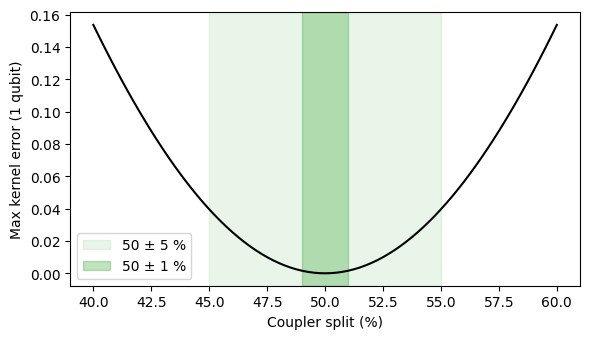

In [4]:
# how much kernel error a perfect (lossless) coupler with a given split causes
def ideal_coupler(k):
    return np.array([[np.sqrt(1 - k), 1j * np.sqrt(k)], [1j * np.sqrt(k), np.sqrt(1 - k)]])

splits = np.linspace(0.40, 0.60, 81)
errs = [kernel_error(ideal_coupler(k)) for k in splits]
for k in (0.50, 0.49, 0.45):
    print(f"split {100*k:.0f}%: max kernel error {kernel_error(ideal_coupler(k)):.4f}")

plt.figure(figsize=(6, 3.5))
plt.plot(100 * splits, errs, "k")
plt.axvspan(45, 55, color="tab:green", alpha=0.1, label="50 ± 5 %")
plt.axvspan(49, 51, color="tab:green", alpha=0.3, label="50 ± 1 %")
plt.xlabel("Coupler split (%)")
plt.ylabel("Max kernel error (1 qubit)")
plt.legend()
plt.tight_layout()
plt.show()

Double coupler: max error 0.0020 at 1550 nm, 0.0276 across the band
Uncoupled (1% split): max error 0.9036 at 1550 nm, 0.9207 across the band
Double coupler retuned: max error 0.0047 across the band


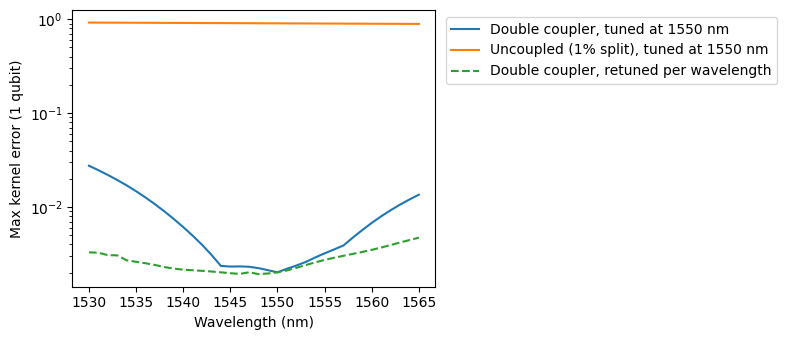

In [5]:
# kernel error across the band: heaters tuned once at 1550 nm vs retuned at every wavelength
plt.figure(figsize=(8, 3.5))
for name, T in couplers.items():
    fixed = np.array([kernel_error(T[w], cal[name]) for w in range(len(wl))])
    plt.plot(wl * 1e3, np.maximum(fixed, 1e-6), label=f"{name}, tuned at 1550 nm")
    print(f"{name}: max error {fixed[i_ref]:.4f} at 1550 nm, {fixed.max():.4f} across the band")

T = couplers["Double coupler"]
retuned = np.array([kernel_error(T[w], calibrate(T[w])) for w in range(len(wl))])  # takes ~1 min
plt.plot(wl * 1e3, np.maximum(retuned, 1e-6), "--", label="Double coupler, retuned per wavelength")
print(f"Double coupler retuned: max error {retuned.max():.4f} across the band")

plt.yscale("log")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Max kernel error (1 qubit)")
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

In [6]:
# quantum kernel SVM on the breast cancer dataset, 8 features = 8 qubits
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = load_breast_cancer(return_X_y=True)
X = PCA(8).fit_transform(StandardScaler().fit_transform(X))
X = (np.pi / 2) * (X - X.min(0)) / (X.max(0) - X.min(0))  # scale features to angles in [0, pi/2]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

def svm_accuracy(kernel_fn):
    clf = SVC(kernel="precomputed", C=10).fit(kernel_fn(X_tr, X_tr), y_tr)
    return clf.score(kernel_fn(X_te, X_tr), y_te)

K_ideal = ideal_kernel_matrix(X_te, X_tr)
print(f"ideal kernel: {100*svm_accuracy(ideal_kernel_matrix):.1f}%")
for name, T in couplers.items():
    for w_nm in (1530, 1550, 1565):
        w = np.argmin(np.abs(wl * 1e3 - w_nm))
        kf = lambda A, B: chip_kernel_matrix(A, B, T[w], cal[name])
        diff = np.abs(kf(X_te, X_tr) - K_ideal)
        print(f"{name} @ {w_nm} nm: {100*svm_accuracy(kf):.1f}%  (mean error {diff.mean():.4f}, max {diff.max():.4f})")

ideal kernel: 97.1%
Double coupler @ 1530 nm: 96.5%  (mean error 0.1051, max 0.1379)
Double coupler @ 1550 nm: 97.1%  (mean error 0.0006, max 0.0029)
Double coupler @ 1565 nm: 97.1%  (mean error 0.0341, max 0.0512)
Uncoupled (1% split) @ 1530 nm: 56.1%  (mean error 0.4524, max 0.5895)
Uncoupled (1% split) @ 1550 nm: 55.0%  (mean error 0.5263, max 0.6644)
Uncoupled (1% split) @ 1565 nm: 55.0%  (mean error 0.5744, max 0.7124)


In [7]:
# summary
dc, bad = couplers["Double coupler"], couplers["Uncoupled (1% split)"]
dc_err = np.array([kernel_error(dc[w], cal["Double coupler"]) for w in range(len(wl))])
band = [np.argmin(np.abs(wl * 1e3 - w_nm)) for w_nm in (1530, 1550, 1565)]
dc_acc = [svm_accuracy(lambda A, B: chip_kernel_matrix(A, B, dc[w], cal["Double coupler"])) for w in band]
bad_acc = svm_accuracy(lambda A, B: chip_kernel_matrix(A, B, bad[i_ref], cal["Uncoupled (1% split)"]))
ideal_acc = svm_accuracy(ideal_kernel_matrix)

print("Bonus results")
print(f"- At 1550 nm the chip kernel is within {dc_err[i_ref]:.4f} of the ideal kernel per qubit,")
print(f"  and the 8-qubit SVM gets {100*dc_acc[1]:.1f}% (ideal kernel: {100*ideal_acc:.1f}%).")
print(f"- Across 1530 to 1565 nm the SVM stays at {100*min(dc_acc):.1f}% to {100*max(dc_acc):.1f}%, but the kernel")
print(f"  error grows toward the band edges (up to {dc_err.max():.4f} per qubit) because the split drifts")
print(f"  and the coupler's phase changes with wavelength.")
print(f"- Retuning the heaters at each wavelength brings the worst error to {retuned.max():.4f} per qubit.")
print(f"- With a coupler that barely splits the light (1%), accuracy drops to {100*bad_acc:.1f}%, about a coin flip.")
print("- This kernel has no entanglement (each qubit is rotated on its own), so a normal computer can")
print("  also compute it. The point is that our MZIs perform the single-qubit gates accurately, which")
print("  larger photonic quantum circuits are built from.")

Bonus results
- At 1550 nm the chip kernel is within 0.0020 of the ideal kernel per qubit,
  and the 8-qubit SVM gets 97.1% (ideal kernel: 97.1%).
- Across 1530 to 1565 nm the SVM stays at 96.5% to 97.1%, but the kernel
  error grows toward the band edges (up to 0.0276 per qubit) because the split drifts
  and the coupler's phase changes with wavelength.
- Retuning the heaters at each wavelength brings the worst error to 0.0047 per qubit.
- With a coupler that barely splits the light (1%), accuracy drops to 55.0%, about a coin flip.
- This kernel has no entanglement (each qubit is rotated on its own), so a normal computer can
  also compute it. The point is that our MZIs perform the single-qubit gates accurately, which
  larger photonic quantum circuits are built from.


## Simulation of Quantum Kernel
The simulation below connects two MZIs in series. Input data is encoded in the phase difference of each MZI by varying the delta_length parameter. The output gives a probability of the final state given either |0> or |1> as the input.

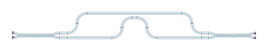

In [18]:
# Second MZI
delta_length2 = -0.125

device2 = mzi(
    gap=gap,
    L1=L1_best,
    L2=L2_best,
    delta_length=delta_length2,
    s_bend_length=s_bend_length,
    s_bend_offset=s_bend_offset,
    arm_length=arm_length,
    arm_radius=arm_radius,
)
viewer(device2)

In [19]:
# Routed arms inside the MZI, lower arm first
routes = next(
    ref.component for ref in device2.references if ref.component.name != double_coupler_component.name
)

# Length of each routed arm (μm)
arm_lengths = [pf.route_length(ref.component) for ref in routes.references]

# Arm length difference achieved by the router (μm)
achieved_delta = arm_lengths[1] - arm_lengths[0]
print(f"Arm lengths: {arm_lengths[0]:.4f} μm (lower), {arm_lengths[1]:.4f} μm (upper)")
print(f"Arm length difference: {achieved_delta:.4f} μm (target {delta_length2:.4f} μm)")

Arm lengths: 173.5532 μm (lower), 173.4292 μm (upper)
Arm length difference: -0.1240 μm (target -0.1250 μm)


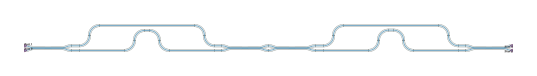

In [20]:
# Connect the two MZIs
kernel_circuit = pf.Component("Quantum_Kernel_Circuit")

mzi1 = kernel_circuit.add_reference(device)
mzi2 = kernel_circuit.add_reference(device2)

mzi2.connect("P0", mzi1["P2"])
mzi2.connect("P1", mzi1["P3"])

kernel_circuit.add_port(
    [
        mzi1["P0"],  # Overall input, bottom rail
        mzi1["P1"],  # Overall input, top rail
        mzi2["P2"],  # Overall output, bottom rail
        mzi2["P3"],  # Overall output, top rail
    ],
    "Port "
)

kernel_circuit.add_model(pf.CircuitModel(), "Circuit")
viewer(kernel_circuit)

In [21]:
# Run FDTD
s_mzi2 = device2.s_matrix(frequencies)

# Assemble a 2x2 transfer matrix
# [P2, P3]
# [P0, P1]
def get_mzi_matrix(s_matrix, wavelength_index):
    return np.array([
        [
            s_matrix["P0@0", "P2@0"][wavelength_index],
            s_matrix["P1@0", "P2@0"][wavelength_index]
        ],
        [
            s_matrix["P0@0", "P3@0"][wavelength_index],
            s_matrix["P1@0", "P3@0"][wavelength_index]
        ]
    ], dtype=complex)

U1 = get_mzi_matrix(s_mzi, i_1550)
U2 = get_mzi_matrix(s_mzi2, i_1550)

print("U1:")
print(U1)
print("\nU2:")
print(U2)

U = U2 @ U1
print("\nTotal transformation U:")
print(U)

c = np.trace(U) / 2
target = c * np.eye(2)
print("\nTarget matrix (c * I):")
print(target)

inverse_error = (
    np.linalg.norm(U - target, ord="fro")
    / np.linalg.norm(target, ord="fro")
    if np.linalg.norm(target, ord="fro") > 0
    else np.inf
)

print(f"\nRelative identity error: {inverse_error:.6f}")

# Output probabilities for an input in the bottom rail |0>
output_bottom = U[0, 0]
output_top = U[1, 0]

P_bottom = abs(output_bottom)**2
P_top = abs(output_top)**2
P_total = P_bottom + P_top

print("\nFor input in bottom rail |0>:")
print(f"Bottom output power: {P_bottom:.8f}")
print(f"Top output power:    {P_top:.8f}")
print(f"Total transmitted:   {P_total:.8f}")

K_conditional = P_bottom / P_total
print(f"Conditional bottom probability: {K_conditional:.8f}")

# Output probabilities for an input in the top rail |1>
output_bottom = U[0, 1]
output_top = U[1, 1]

P_bottom = abs(output_bottom)**2
P_top = abs(output_top)**2
P_total = P_bottom + P_top

print("\nFor input in top rail |1>:")
print(f"Bottom output power: {P_bottom:.8f}")
print(f"Top output power:    {P_top:.8f}")
print(f"Total transmitted:   {P_total:.8f}")

K_conditional = P_top / P_total
print(f"Conditional top probability: {K_conditional:.8f}")

U1:Progress: 100% 

[[ 0.88334603+0.44245378j  0.00559512-0.00293447j]
 [ 0.00559024-0.00292403j -0.08488822+0.98525326j]]

U2:
[[ 0.87248015+0.46306958j -0.01494926+0.00810238j]
 [-0.01495148+0.00811188j -0.108127  +0.98293257j]]

Total transformation U:
[[ 5.65755113e-01+0.79517182j -4.73391502e-04-0.01538594j]
 [-1.45267926e-02+0.00636125j -9.59318661e-01-0.18988262j]]

Target matrix (c * I):
[[-0.19678177+0.3026446j -0.        +0.j       ]
 [-0.        +0.j        -0.19678177+0.3026446j]]

Relative identity error: 2.515010

For input in bottom rail |0>:
Bottom output power: 0.95237708
Top output power:    0.00025149
Total transmitted:   0.95262857
Conditional bottom probability: 0.99973600

For input in top rail |1>:
Bottom output power: 0.00023695
Top output power:    0.95634770
Total transmitted:   0.95658465
Conditional top probability: 0.99975229


In [22]:
wavelength = 1.550

# Run simulation for wavelength 1550nm
S = kernel_circuit.s_matrix([pf.C_0 / wavelength])

# Input |0>
amp_bottom = np.asarray(
    S.elements[("Port 2@0", "Port 0@0")]
)[0]
amp_top = np.asarray(
    S.elements[("Port 3@0", "Port 0@0")]
)[0]

# # Input |1>
# amp_bottom = np.asarray(
#     S.elements[("Port 2@0", "Port 1@0")]
# )[0]
# amp_top = np.asarray(
#     S.elements[("Port 3@0", "Port 1@0")]
# )[0]

power_bottom = np.abs(amp_bottom) ** 2
power_top = np.abs(amp_top) ** 2

total_power = power_bottom + power_top

prob_bottom = power_bottom / total_power
prob_top = power_top / total_power

print("Bottom output probability:", prob_bottom)
print("Top output probability:", prob_top)

Uploading task 'P0@0…'
Uploading task 'P1@0…'
Uploading task 'Mode-Stripwaveguide…'
Uploading task 'Mode-Stripwaveguide…'
Uploading task 'Mode-Stripwaveguide…'
Uploading task 'Mode-Stripwaveguide…'
Starting task 'Mode-Stripwaveguide': https://tidy3d.simulation.cloud/workbench?taskId=mo-266a515d-36a6-49f7-ab97-9399f1acba70
Starting task 'Mode-Stripwaveguide': https://tidy3d.simulation.cloud/workbench?taskId=mo-4dd115fb-5546-47c8-9d9b-6805943a4bb9
Starting task 'Mode-Stripwaveguide': https://tidy3d.simulation.cloud/workbench?taskId=mo-2bec2097-52df-4682-a212-fa7f95e6c2c5
Starting task 'P1@0': https://tidy3d.simulation.cloud/workbench?taskId=fdve-da678daa-c548-48e0-b0a5-a4d68dceb24c
Starting task 'P0@0': https://tidy3d.simulation.cloud/workbench?taskId=fdve-eba8836f-cec2-49fb-9778-c31cff904d57
Starting task 'Mode-Stripwaveguide': https://tidy3d.simulation.cloud/workbench?taskId=mo-8cf0caa4-4053-49c6-a8ee-f079925f724a
Bottom output probability:Progress: 100% 
 0.9992418765244029
Top output

The results show that the two MZIs return the probabilities accurately for |0> and |1> inputs. For both inputs, the correct port has probability less than 0.01% off the theoretical. Since our MZIs are implemented with fixed arms, the phase difference cannot be encoded without changing the geometry. A phase shifter can be used so that any input value can be encoded in the MZIs.